## Setup

In [1]:
import torch
import sys, pickle, warnings
from pathlib import Path
import numpy as np
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from rex_xai.lib import ReX
from rex_xai.responsibility.prediction import from_pytorch_tensor
from rex_xai.input.input_data import Data

In [2]:
# SETUP
ROOT = Path.cwd().parents[1]   # notebooks/bg_exp/ -> project root
DATA = ROOT / "data"
OUT = Path.cwd() / "outputs"   # notebooks/bg_exp/outputs/
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "ConceptBottleneck"))
warnings.filterwarnings("ignore", message="source code of class")

# Setup CUDA device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

# Open Dataset
test_data = pickle.load(open(DATA / "CUB_processed/test.pkl", "rb"))

# Name of the classes
CLASSES = open(DATA / "CUB_200_2011/classes.txt").read().splitlines()
print(f"Classes example: {CLASSES[::15][:5]}")

# The 112 of 312 CUB attributes used by the paper, 0-based (from CUB/generate_new_data.py).
SELECTED_CONCEPTS = [
    1, 4, 6, 7, 10, 14, 15, 20, 21, 23, 25, 29, 30, 35, 36, 38, 40, 44, 45, 50, 51, 53, 54, 56, 57, 59, 63, 64,
    69, 70, 72, 75, 80, 84, 90, 91, 93, 99, 101, 106, 110, 111, 116, 117, 119, 125, 126, 131, 132, 134, 145, 149,
    151, 152, 153, 157, 158, 163, 164, 168, 172, 178, 179, 181, 183, 187, 188, 193, 194, 196, 198, 202, 203, 208,
    209, 211, 212, 213, 218, 220, 221, 225, 235, 236, 238, 239, 240, 242, 243, 244, 249, 253, 254, 259, 260, 262,
    268, 274, 277, 283, 289, 292, 293, 294, 298, 299, 304, 305, 308, 309, 310, 311,
]

# Get Concepts list
CONCEPTS = open(DATA / "CUB_200_2011/attributes/attributes.txt").read().splitlines()

# Concepts used in the model training as a list
CONCEPT_NAMES = [CONCEPTS[i].split(" ")[1] for i in SELECTED_CONCEPTS]
assert len(CONCEPT_NAMES) == 112

# Load models
joint_model_path = DATA / "models" / "Joint0.01Model__Seed1" / "best_model_1.pth"
joint_model = torch.load(joint_model_path, map_location=torch.device(device), weights_only=False)
joint_model.eval()

concept_model_path = DATA / "models" / "ConceptModel__Seed1" / "best_model_1.pth"
concept_model = torch.load(concept_model_path, map_location=torch.device(device), weights_only=False)
concept_model.eval()

independent_head_path = DATA / "models" / "IndependentModel_WithVal___Seed1" / "best_model_1.pth"
independent_head = torch.load(independent_head_path, map_location=torch.device(device), weights_only=False)
independent_head.eval()

sequential_head_path = DATA / "models" / "SequentialModel_WithVal__Seed1" / "best_model_1.pth"
sequential_head = torch.load(sequential_head_path, map_location=torch.device(device), weights_only=False)
sequential_head.eval()

cuda NVIDIA GeForce RTX 4070 Laptop GPU
Classes example: ['1 001.Black_footed_Albatross', '16 016.Painted_Bunting', '31 031.Black_billed_Cuckoo', '46 046.Gadwall', '61 061.Heermann_Gull']


MLP(
  (linear): Linear(in_features=112, out_features=200, bias=True)
)

## Helpers: images and data

In [3]:
# Helpers: images and data
resol = 299

def crop_image(img, resol):
    transform = transforms.Compose([
        transforms.CenterCrop(resol)
    ])

    return transform(img)

def to_tensor(img):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
    ])

    return transform(img)

def get_image_path_from_index(index, dataset=test_data):
    img_path = DATA / "CUB_200_2011" / dataset[index]["img_path"].split("CUB_200_2011/")[-1]
    return str(img_path)

def get_image_from_index(index, dataset=test_data):
    """
    Get the image from the test dataset given an index.
    """
    return Image.open(get_image_path_from_index(index, dataset)).convert("RGB")

def get_bird_mask(index, resol=299):
    segmentation_path = Path(get_image_path_from_index(index).replace("/images/", "/segmentations/")).with_suffix(".png")
    seg_img = Image.open(segmentation_path).convert("L")
    cropped_seg_img = crop_image(seg_img, resol)

    cropped_tensor = torch.from_numpy(np.array(cropped_seg_img))

    return (cropped_tensor > 127).to(device)

def get_class_name(class_idx):
    return CLASSES[class_idx].strip().split(" ")[1]

def get_class_from_index(index, dataset=test_data):
    return get_class_name(dataset[index]["class_label"])

def get_concepts_from_index(index, dataset=test_data):
    """
    Get the names of the concepts labelled present for a test image, given its index.
    """

    labels = dataset[index]["attribute_label"]

    present_concepts = []
    for name, label in zip(CONCEPT_NAMES, labels):
        if label == 1:
            present_concepts.append(name)
    
    return present_concepts




## Helpers: models

`run_model`, `get_top_k_class_pred`, `get_found_concepts` (cell below), and later `evaluate`.

In [4]:

def run_model(model_name, img):
    """
    Run the model on the image and return the predicted class and concepts.
    """

    if img.dim() == 3:
        # Add batch dimension
        img = img.unsqueeze(0)

    # Move to device
    img = img.to(device)

    # Run the model
    with torch.no_grad():
        if model_name == "joint":
            out = joint_model(img)
            raw_concepts = torch.concat(out[1:], dim=1)
            class_scores = out[0]

        elif model_name == "independent":
            raw_concepts = torch.cat(concept_model(img), dim=1)
            class_scores = independent_head(torch.sigmoid(raw_concepts))

        elif model_name == "sequential":
            raw_concepts = torch.cat(concept_model(img), dim=1)      
            class_scores = sequential_head(raw_concepts)

        else:
            raise ValueError(f"Unknown model name: {model_name}")
        
    class_scores = torch.softmax(class_scores, dim=1)
    return class_scores, raw_concepts



def get_top_k_class_pred(class_scores, top_k):
    """
    Get the top-k predictions labels and confidence
    """
    
    top_k_scores, top_k_idxs = torch.topk(class_scores, top_k)
    top_k_predictions = {}

    for i in range(top_k):
        class_index = top_k_idxs[0][i].item()
        class_score = top_k_scores[0][i].item()
        class_name = get_class_name(class_index)

        top_k_predictions[class_name] = class_score

    return top_k_predictions


def get_found_concepts(raw_concepts, index, dataset=test_data, verbose=True):
    """
    Compare the predicted concepts to the labels and return the number that match.
    """
    concept_labels = torch.tensor(dataset[index]["attribute_label"], device=device).bool()
    concepts_prob = torch.sigmoid(raw_concepts)[0]
    predicted_concepts = concepts_prob > 0.5

    matches = (predicted_concepts == concept_labels).sum().item()

    if verbose:
        print(f"    Matching concepts: {matches}/{len(concept_labels)}")
        print(f"    Predicted present: {predicted_concepts.sum().item()}, truly present: {concept_labels.sum().item()}")

    return matches
 
def evaluate(img, idx, model_name="joint", top_k_pred=3):
    """ 
    Run the model on img 
    return a dict: top-k, true-class prob, concept probs (sigmoid), matches.
    """
    results = {}

    class_scores, raw_concepts = run_model(model_name, img)
    concepts_probs = torch.sigmoid(raw_concepts)[0]

    predictions = get_top_k_class_pred(class_scores, top_k_pred)
    found_concepts = get_found_concepts(raw_concepts, idx, verbose=False)

    top_class_pred = max(predictions, key=predictions.get)
    top_class_conf = predictions[top_class_pred]

    true_class = get_class_from_index(idx, test_data)
    true_class_confidence = class_scores[0, test_data[idx]["class_label"]].item()

    results["top_class_pred"] = top_class_pred
    results["top_class_conf"] = top_class_conf
    results["top_k_pred"] = predictions
    results["true_class"] = true_class
    results["true_class_conf"] = true_class_confidence
    results["concepts_prob"] = concepts_probs
    results["concept_matches"] = found_concepts

    return results


def compare_concepts(probs_a, probs_b, top_n=5):
    # How many concepts cross 0.5 probability between the two lists
    n_flipped = ((probs_a > 0.5) != (probs_b > 0.5)).sum().item()
    
    # Change per concept, and its average
    change = (probs_b - probs_a).abs()  # [112]
    mean_change = change.mean().item()

    # Top n concepts with the largest absolute change
    top_changes = []
    values, positions = torch.topk(change, top_n)
    
    for i in positions.tolist():
        top_changes.append((CONCEPT_NAMES[i], probs_a[i].item(), probs_b[i].item()))

    return n_flipped, mean_change, top_changes




## Helpers: swapping

`get_input`, `make_composite`, later `swap_test`.

In [5]:
def get_input(idx):
    """Returns (cropped PIL image, normalised [3, 299, 299] tensor on device, bird mask)."""
    
    # Get bird image
    bird_img = crop_image(get_image_from_index(idx, test_data), resol)
    bird_img_tensor = to_tensor(bird_img).to(device)

    # Get Bird Mask
    bird_mask = get_bird_mask(idx, resol)

    return bird_img, bird_img_tensor, bird_mask


def make_collage(img, mask, background):
    """ Returns the tensor for the image of a background with the cropped bird"""
    return torch.where(mask, img, background)


## Helpers: plotting

In [6]:
# Helpers: plotting
def tensor_to_img(x):
    """Normalised tensor -> PIL image for viewing (does not change the tensor)."""
    x = x.squeeze(0).cpu() * 2 + 0.5   # undo Normalize(mean=0.5, std=2)
    return transforms.functional.to_pil_image(x.clamp(0, 1))

def plot_img_and_seg(img, bird, save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    #cropped image
    axes[0].imshow(img)

    # Masked Image
    bird_np = bird.cpu().numpy()
    axes[1].imshow(bird_np, cmap="gray")

    # Cropped image with mask on top
    axes[2].imshow(img)
    axes[2].imshow(bird_np, alpha=0.4, cmap="Reds")

    titles = ["Image", f"Bird mask ({bird.float().mean().item():.0%} of image)", "Overlay"]
    for axis, title in zip(axes, titles):
        axis.set_title(title) 
        axis.axis("off")

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    plt.show()

## Helpers: ReX

In [7]:
def joint_prediction_function(mutants, target=None, raw=False):
    with torch.no_grad():
        class_logits = joint_model(mutants)[0]

    if raw:
        return torch.softmax(class_logits, dim=1)
    else:
        return from_pytorch_tensor(class_logits, target=target)
    

def run_rex_seeds(rex, seeds, threshold=0.0):
    masks = {}
    stats = {}
    rex.args.minimum_confidence_threshold = threshold

    for seed in seeds:
        rex.args.seed = seed
        rex.calculate_responsibility().generate_explanation_object()
        stats[seed] = dict(rex.stats)
        rex.extract_sufficient_explanation()

        mask = rex.explanation.sufficiency_mask
        assert (mask[0] == mask[1]).all() and (mask[0] == mask[2]).all()  # all 3 channels identical
        masks[seed] = mask[0].clone()                                      # keep one [299, 299] channel

    return masks, stats


def bird_share(explanation, bird):
    share = (explanation & bird).sum() / explanation.sum()
    size = explanation.float().mean().item()

    return size, share.item()


def plot_seed_overlays(img, bird, masks, save_path=None):
    seeds = list(masks.keys())
    fig, axes = plt.subplots(1, len(seeds), figsize=(4 * len(seeds), 4))
    axes = np.atleast_1d(axes)                        # works for 1 seed too
    bird_np = bird.cpu().numpy()                      # GPU tensor → numpy, as before

    for axis, seed in zip(axes, seeds):
        explanation = masks[seed].cpu().numpy()  
        
        on = explanation & bird_np    # explanation pixels that are bird
        off = explanation & ~bird_np  # explanation pixels that are not bird
        
        overlay = np.zeros((*explanation.shape, 4))   # RGBA layer
        overlay[on] = [0, 1, 0, 0.5]   # green
        overlay[off] = [1, 0, 0, 0.5]  # red

        # fraction of the image the explanation covers
        # fraction of the explanation on the bird
        size, share = bird_share(masks[seed], bird)
        
        axis.imshow(img)
        axis.imshow(overlay)
        axis.set_title(f"seed {seed}: {size:.1%} of image, {share:.0%} on bird")
        axis.axis("off")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

## Experiments
### 1- Grey Background Experiment

In [8]:
def grey_bg_experiment(idx_list):
    
    for idx in idx_list:

        # Setup image and mask
        img_pil, img, mask = get_input(idx)
        plot_img_and_seg(img_pil, mask)

        # Show Collage Image (background + image)
        grey_bg_collage = make_collage(img, mask, torch.zeros_like(img))
        tensor_to_img(grey_bg_collage)

        # Run model on original image
        original = evaluate(img, idx)

        # Run Model on Grey backgroud + Bird
        grey = evaluate(grey_bg_collage, idx)

        for name, r in [("original", original), ("grey", grey)]:
            print(f"{name} | Top Pred: {r["top_class_pred"]} - Top Pred Conf: {r['top_class_conf']:.4f} | True Class: {r['true_class']} - True Class Conf: {r['true_class_conf']:.4f}")

        n_flipped, mean_change, top_changes = compare_concepts(original["concepts_prob"], grey["concepts_prob"])
        print(f"flipped: {n_flipped} | mean change: {mean_change:.3f}")
        for name, before, after in top_changes:
            print(f"  {name:45} {before:.2f} -> {after:.2f}")



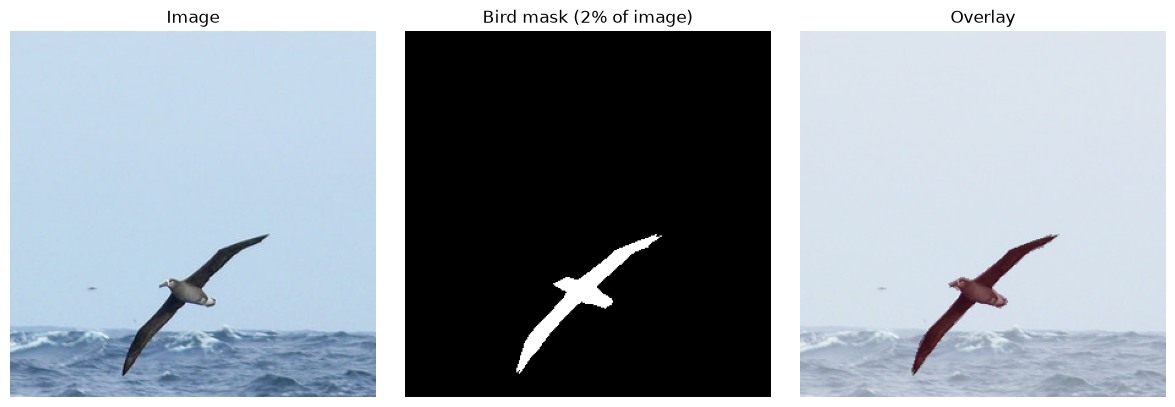

original | Top Pred: 072.Pomarine_Jaeger - Top Pred Conf: 0.4730 | True Class: 001.Black_footed_Albatross - True Class Conf: 0.0335
grey | Top Pred: 078.Gray_Kingbird - Top Pred Conf: 0.1173 | True Class: 001.Black_footed_Albatross - True Class Conf: 0.0048
flipped: 14 | mean change: 0.127
  has_size::medium_(9_-_16_in)                  0.86 -> 0.21
  has_breast_color::white                       0.12 -> 0.74
  has_bill_color::black                         0.26 -> 0.86
  has_shape::perching-like                      0.02 -> 0.60
  has_upperparts_color::black                   0.79 -> 0.27


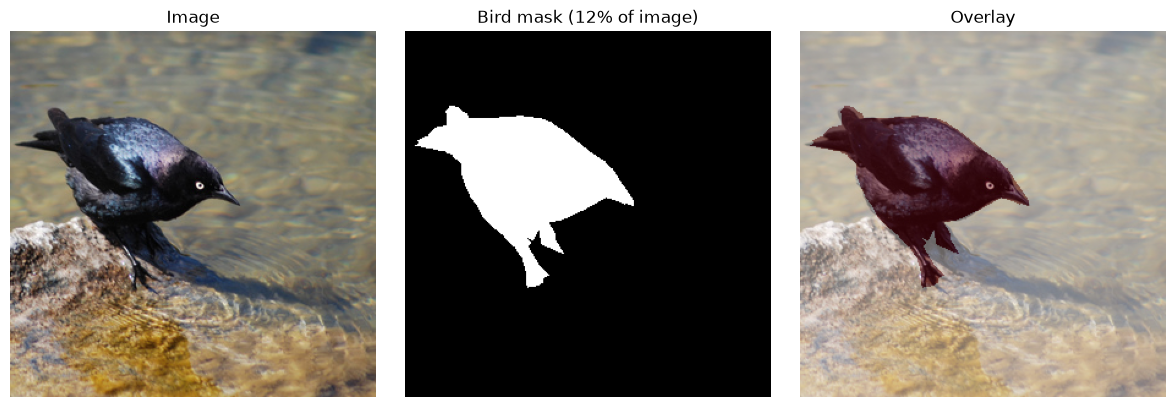

original | Top Pred: 049.Boat_tailed_Grackle - Top Pred Conf: 0.9248 | True Class: 009.Brewer_Blackbird - True Class Conf: 0.0382
grey | Top Pred: 049.Boat_tailed_Grackle - Top Pred Conf: 0.9927 | True Class: 009.Brewer_Blackbird - True Class Conf: 0.0036
flipped: 4 | mean change: 0.036
  has_nape_color::black                         0.83 -> 0.19
  has_back_color::black                         0.73 -> 0.13
  has_leg_color::grey                           0.44 -> 0.91
  has_wing_shape::rounded-wings                 0.46 -> 0.90
  has_wing_pattern::solid                       0.46 -> 0.09


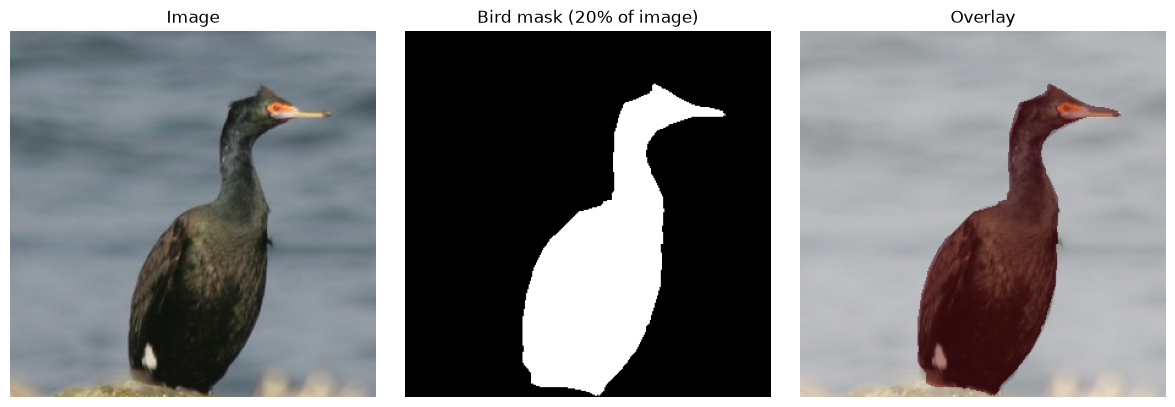

original | Top Pred: 025.Pelagic_Cormorant - Top Pred Conf: 0.9909 | True Class: 024.Red_faced_Cormorant - True Class Conf: 0.0047
grey | Top Pred: 024.Red_faced_Cormorant - Top Pred Conf: 0.8282 | True Class: 024.Red_faced_Cormorant - True Class Conf: 0.8282
flipped: 2 | mean change: 0.025
  has_head_pattern::plain                       0.91 -> 0.22
  has_bill_shape::hooked_seabird                0.04 -> 0.65
  has_bill_color::black                         0.89 -> 0.60
  has_wing_pattern::solid                       0.97 -> 0.86
  has_bill_length::about_the_same_as_head       0.98 -> 0.89


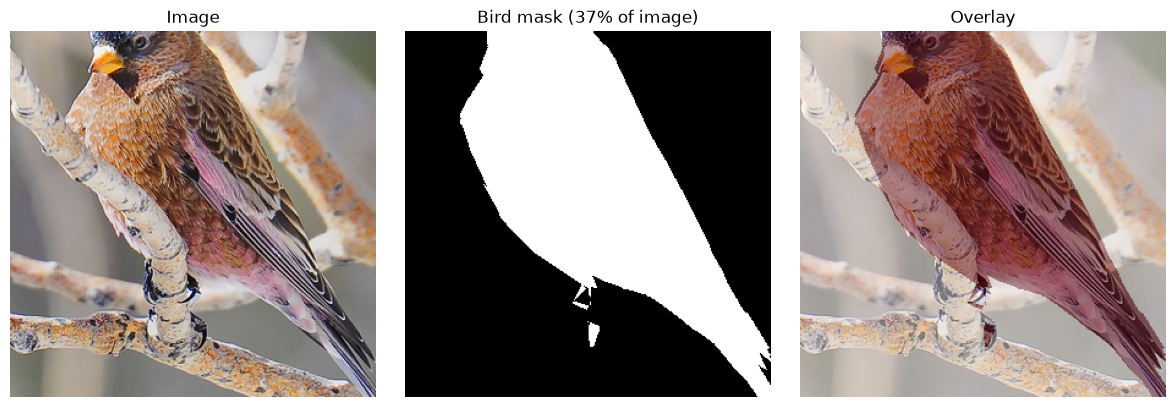

original | Top Pred: 034.Gray_crowned_Rosy_Finch - Top Pred Conf: 1.0000 | True Class: 034.Gray_crowned_Rosy_Finch - True Class Conf: 1.0000
grey | Top Pred: 034.Gray_crowned_Rosy_Finch - Top Pred Conf: 1.0000 | True Class: 034.Gray_crowned_Rosy_Finch - True Class Conf: 1.0000
flipped: 0 | mean change: 0.002
  has_eye_color::black                          0.77 -> 0.82
  has_breast_pattern::solid                     0.06 -> 0.04
  has_belly_pattern::solid                      0.05 -> 0.04
  has_bill_color::black                         0.02 -> 0.01
  has_back_color::grey                          0.02 -> 0.01


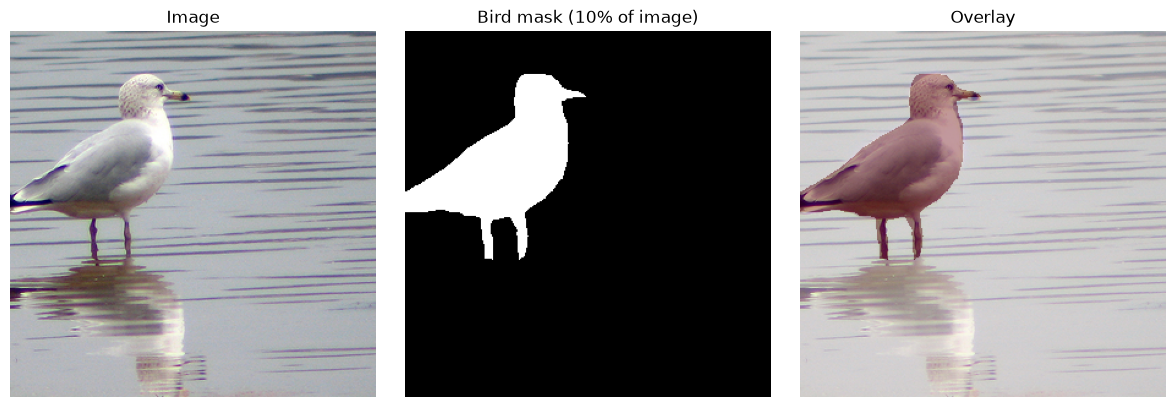

original | Top Pred: 064.Ring_billed_Gull - Top Pred Conf: 0.7268 | True Class: 064.Ring_billed_Gull - True Class Conf: 0.7268
grey | Top Pred: 145.Elegant_Tern - Top Pred Conf: 0.4770 | True Class: 064.Ring_billed_Gull - True Class Conf: 0.0301
flipped: 3 | mean change: 0.052
  has_bill_shape::hooked_seabird                0.94 -> 0.39
  has_wing_color::grey                          0.98 -> 0.46
  has_bill_shape::dagger                        0.01 -> 0.48
  has_primary_color::grey                       0.98 -> 0.54
  has_tail_pattern::multi-colored               0.31 -> 0.73


In [9]:
idx_list = [0, 200, 600, 900, 1800]
grey_bg_experiment(idx_list)

**Notes**
- idx 0: grey prediction Gray Kingbird (conf = 0.47) $\ne$ Original Prediction --> The bird is a small part of the image. Without the sea background it predicts a land bird
- idx 200: Grey prediction (Grackle) $\ne$ Original Prediction (Boat-tailed Grackle - wrong) --> Wrong both times, grey background made it more confident
- idx 600: Grey Prediction (Red-faced Cormorant - CORRECT) $\ne$ Original prediction (Pelagic Cormorant - WRONG) --> Removing the background fixed the prediction. The background moved the prediction towards the wrong Cormorant type
- idx 900: Grey Prediction (Rosy Finch - conf = 1 - CORRECT) $=$ Original Prediction (Rosy Finch - conf = 1 - CORRECT) --> Unaffected, close-up and greyisih original background
- idx 1800: Grey Prediction (Elegant Tern - conf = 0.48 - INCORRECT) $\ne$ Correct Prediction (Ring-Billed Gull - conf = 0.73 - CORRECT) --> Moved from correct to wrong

### 2- Different Background Colours

In [9]:
def make_backgrounds(img):

    backgrounds = {
        "grey": torch.zeros_like(img),
        "black": (torch.zeros_like(img) - 0.5)/2,
        "white": (torch.ones_like(img) - 0.5)/2,
        "blur": transforms.functional.gaussian_blur(img, kernel_size=51, sigma=20)
    }
    return backgrounds


def plot_composites(composites, labels=None, save_path=None):
    """One row of images: {name: [3, 299, 299] normalised tensor}. labels: optional {name: extra title text}."""
    fig, axes = plt.subplots(1, len(composites), figsize=(4 * len(composites), 4))
    axes = np.atleast_1d(axes)
        
    for axis, (name, x) in zip(axes, composites.items()):
        axis.imshow(tensor_to_img(x))
        title = name if labels is None else f"{name}\n{labels[name]}"
        axis.set_title(title, fontsize=10)
        axis.axis("off")
            
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show() 


def swap_test(idx_list, model_name="joint", plot=False):
    rows = []
    for idx in idx_list:
        img_pil, img, mask = get_input(idx)
        original = evaluate(img, idx, model_name=model_name)

        composites = {"original": img}
        for bg_name, bg in make_backgrounds(img).items():
            composites[bg_name] = make_collage(img, mask, bg)          # bird pasted on bg

        for bg_name, x in composites.items():
            r = evaluate(x, idx, model_name=model_name)
            n_flipped, mean_change, top_changes = compare_concepts(original["concepts_prob"], r["concepts_prob"])
            rows.append({
                "idx": idx, 
                "background": bg_name,
                "true_class": r["true_class"],
                "top_pred": r["top_class_pred"],           
                "top_conf": r["top_class_conf"],
                "true_conf": r["true_class_conf"],
                "correct": r["top_class_pred"] == r["true_class"],               # bool: top prediction == true class
                "n_flipped": n_flipped,
                "mean_change": mean_change,
                "top_changes": top_changes,
                "bird_frac": mask.float().mean().item(),         # bird share of the image (chance baseline)
                "concepts": r["concepts_prob"].cpu().numpy(),     # all 112 concept probs, for later analysis
            })

        if plot:
            labels = {row["background"]: f"{row['top_pred']} {row['top_conf']:.2f}"
                        for row in rows if row["idx"] == idx}
            plot_composites(composites, labels)

    return rows

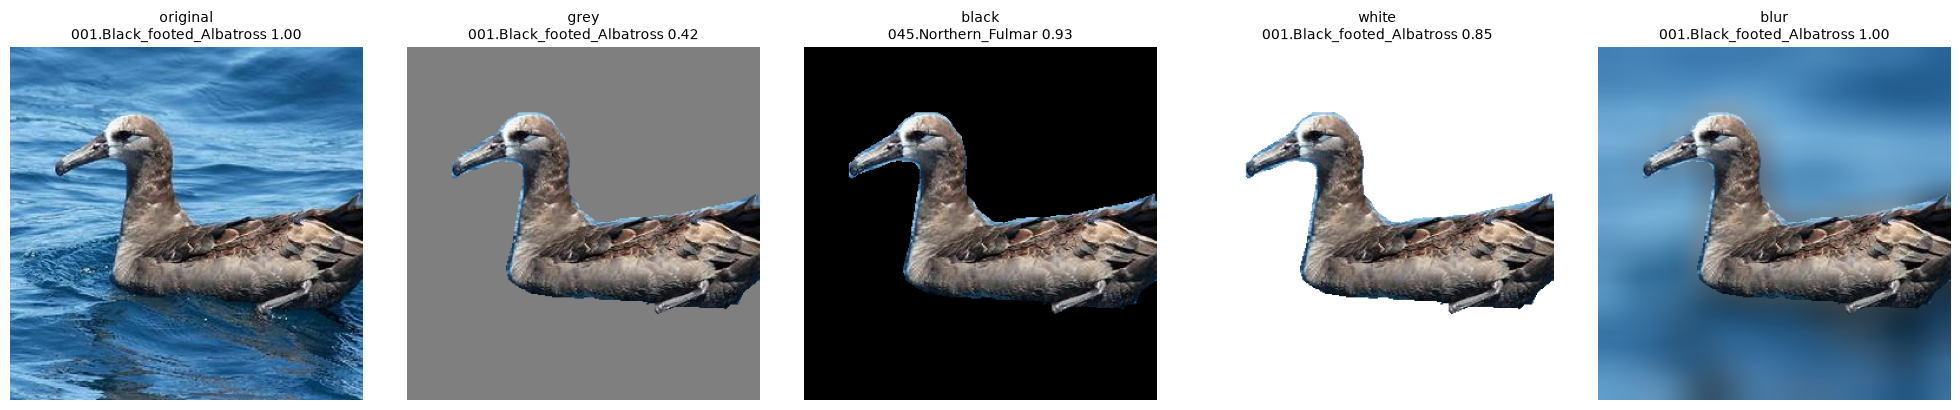

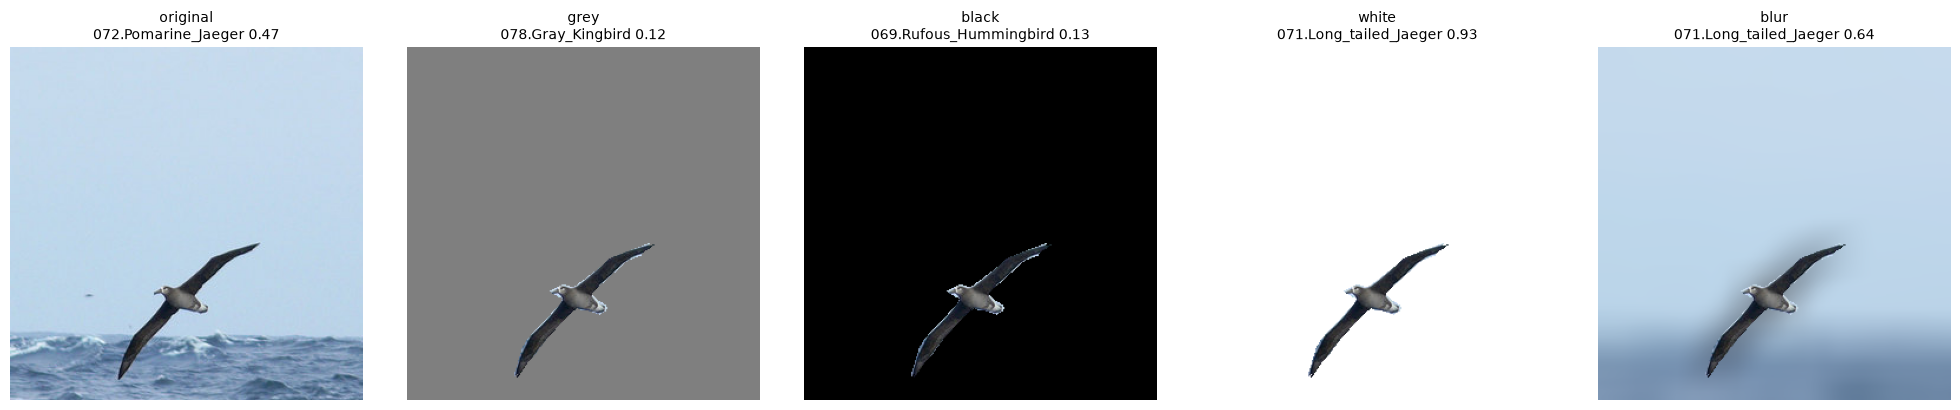

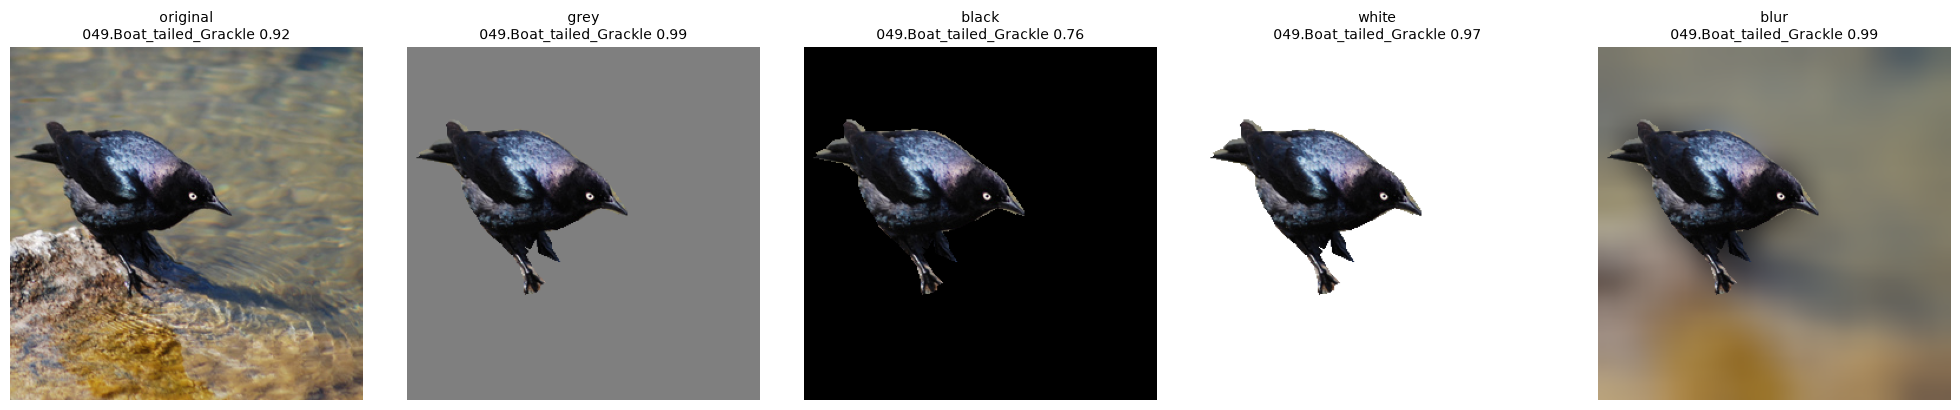

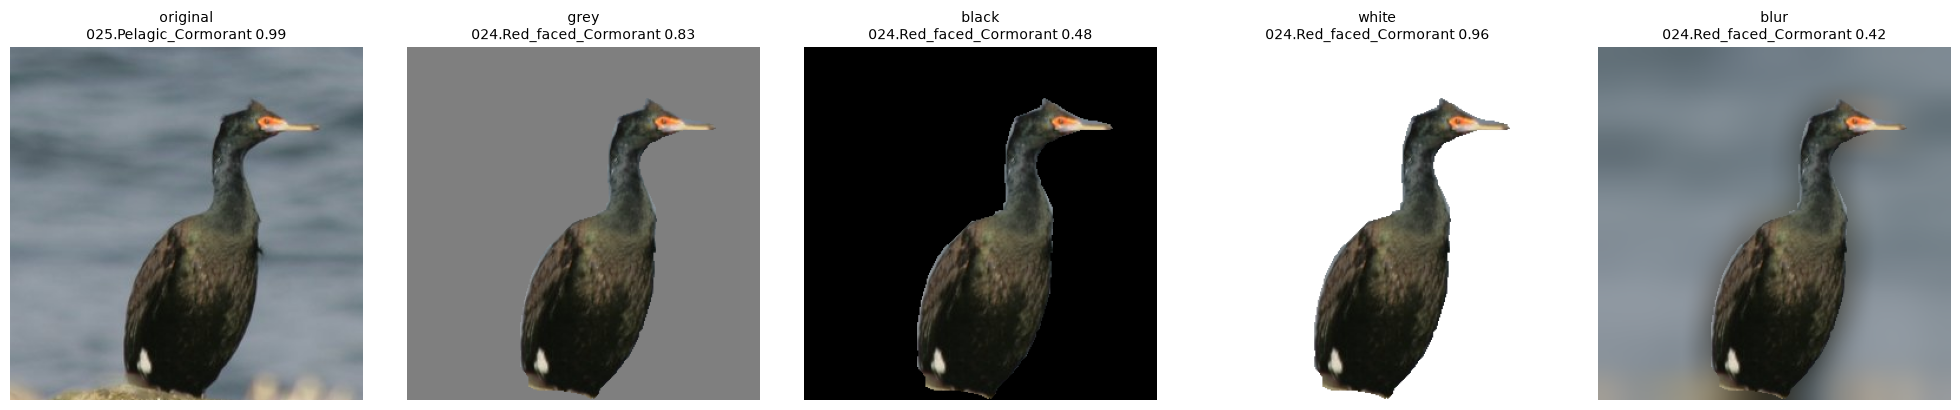

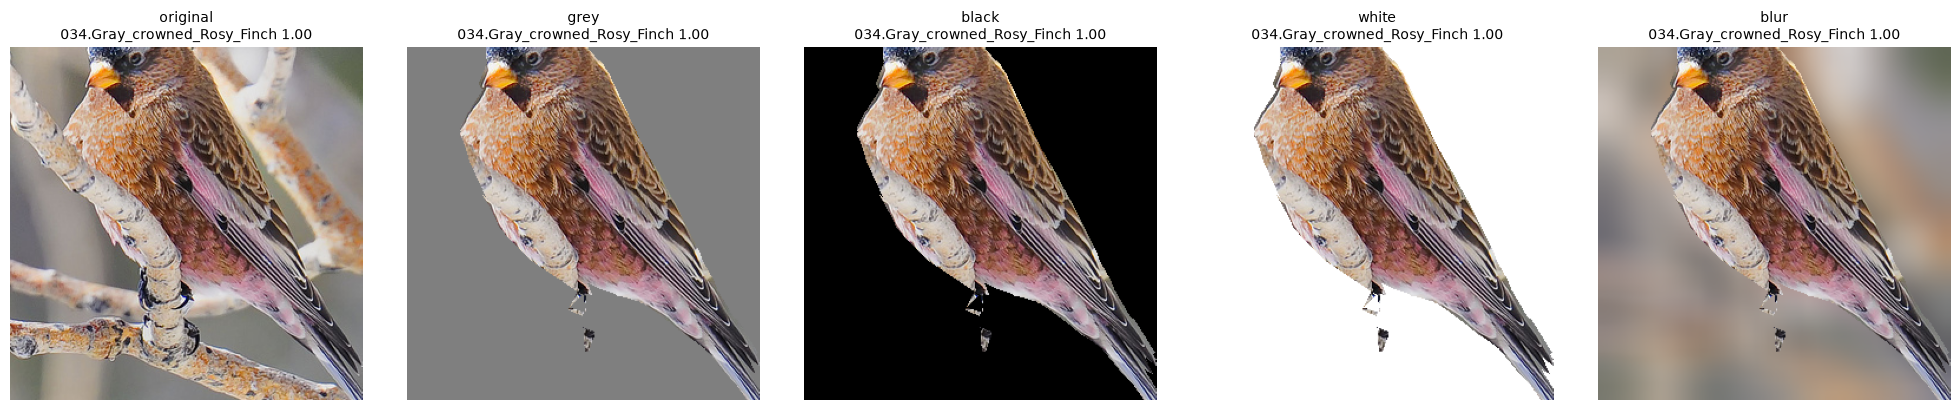

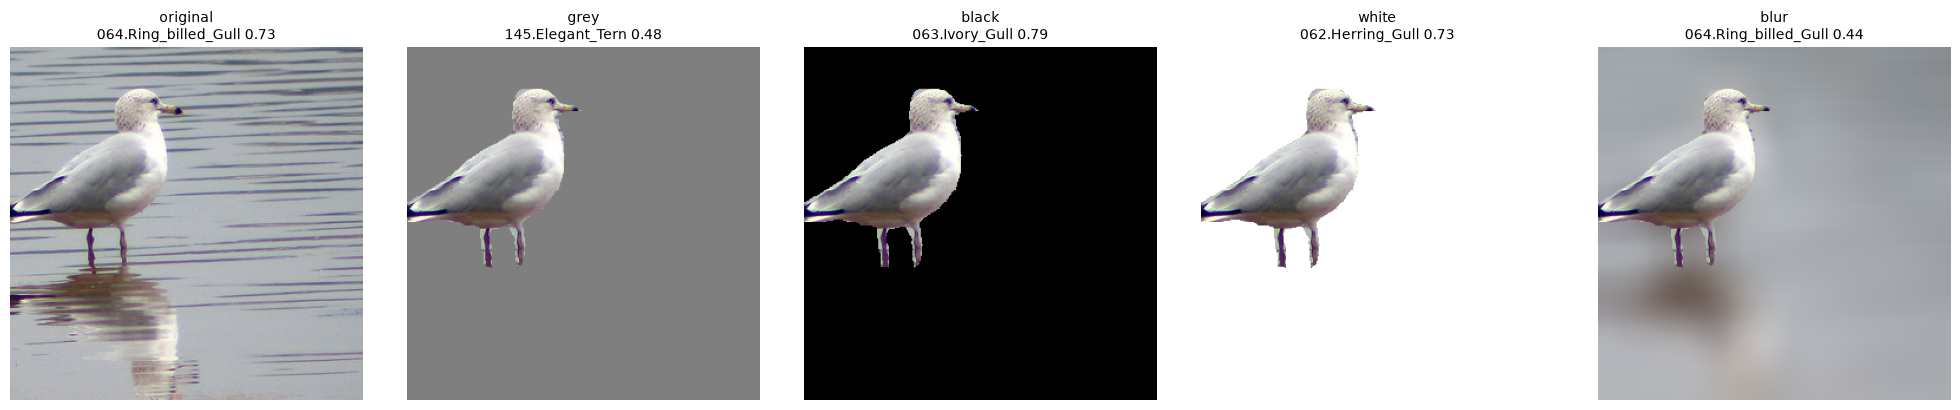

,idx,background,true_class,top_pred,top_conf,true_conf,correct,n_flipped,mean_change
0,10,original,001.Black_footed_Albatross,001.Black_footed_Albatross,0.999875,0.999875,True,0,0.000000
1,10,grey,001.Black_footed_Albatross,001.Black_footed_Albatross,0.422762,0.422762,True,8,0.072753
2,10,black,001.Black_footed_Albatross,045.Northern_Fulmar,0.933512,0.028627,False,18,0.132214
3,10,white,001.Black_footed_Albatross,001.Black_footed_Albatross,0.852371,0.852371,True,0,0.044828
4,10,blur,001.Black_footed_Albatross,001.Black_footed_Albatross,0.997219,0.997219,True,0,0.009906
5,0,original,001.Black_footed_Albatross,072.Pomarine_Jaeger,0.472976,0.033469,False,0,0.000000
6,0,grey,001.Black_footed_Albatross,078.Gray_Kingbird,0.117322,0.004796,False,14,0.127110
7,0,black,001.Black_footed_Albatross,069.Rufous_Hummingbird,0.129651,0.019475,False,13,0.130576
8,0,white,001.Black_footed_Albatross,071.Long_tailed_Jaeger,0.932871,0.001119,False,10,0.069086
9,0,blur,001.Black_footed_Albatross,071.Long_tailed_Jaeger,0.639010,0.029716,False,6,0.068160


In [11]:
rows = swap_test([10, 0, 200, 600, 900, 1800], plot=True)
df = pd.DataFrame(rows)
df.drop(columns="top_changes")

In [12]:
for _, row in df[df.idx == 10].iterrows():
    print(row.background, row.top_changes)

original [('has_bill_shape::hooked_seabird', 0.9978867173194885, 0.9978867173194885), ('has_bill_shape::dagger', 3.7542708014370874e-05, 3.7542708014370874e-05), ('has_bill_shape::all-purpose', 0.0034693977795541286, 0.0034693977795541286), ('has_wing_color::brown', 0.002004641806706786, 0.002004641806706786), ('has_bill_shape::cone', 0.003042493248358369, 0.003042493248358369)]
grey [('has_underparts_color::grey', 0.9949690699577332, 0.11021584272384644), ('has_underparts_color::white', 0.032880499958992004, 0.8237572312355042), ('has_nape_color::white', 0.012641537934541702, 0.7212194204330444), ('has_belly_color::white', 0.02994682267308235, 0.6991950273513794), ('has_breast_color::white', 0.010124250315129757, 0.6704201698303223)]
black [('has_underparts_color::grey', 0.9949690699577332, 0.07164029031991959), ('has_nape_color::white', 0.012641537934541702, 0.9315162301063538), ('has_underparts_color::white', 0.032880499958992004, 0.9139826893806458), ('has_breast_color::white', 0.0

### 3- ReX Explanations on Different Backgrounds

In [10]:
model_shape = ["N", 3, resol, resol]


def setup_rex_from_tensor(x, model, prediction_function):
    rex = ReX(model, model_shape, device, "RGB", prediction_function)
    rex.data = Data(tensor_to_img(x), model_shape, device, mode="RGB")           # PIL, used for plotting
    rex.set_transformed_data(x.unsqueeze(0).to(device))
    rex.set_target()
    return rex


def plot_explanations(composites, rows, bird, save_path=None):
      """One panel per row: composite with its ReX explanation on top (green = on bird, red = off bird)."""
      bird = bird.cpu().bool()
      fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4.5))
      axes = np.atleast_1d(axes)
  
      for axis, row in zip(axes, rows):
          expl = row["explanation"].bool()
          overlay = np.zeros((*expl.shape, 4))              # RGBA, transparent everywhere
          overlay[(expl & bird).numpy()] = [0, 1, 0, 0.5]   # on bird
          overlay[(expl & ~bird).numpy()] = [1, 0, 0, 0.5]  # off bird
 
          axis.imshow(tensor_to_img(composites[row["background"]]))
          axis.imshow(overlay)
          axis.set_title(f"{row['background']}\n{row['target_class']} {row['target_conf']:.2f}\n"
                         f"size {row['size']:.1%} | bird {row['bird_share']:.0%}", fontsize=9)
          axis.axis("off")

      plt.tight_layout() 
      if save_path is not None:
          fig.savefig(save_path, dpi=150, bbox_inches="tight")
      plt.show()
  


def rex_swap_test(idx_list, model, prediction_function, threshold=0.9, seed=0, skip=("grey",), plot=False):
    rows = []

    for idx in idx_list:
        img_pil, img, mask = get_input(idx)
        true_class = get_class_from_index(idx)

        # Build Composites
        composites = {"original": img}
        for bg_name, bg in make_backgrounds(img).items():
            composites[bg_name] = make_collage(img, mask, bg)

        for bg_name, x in composites.items():
            if bg_name in skip:
                continue

            rex = setup_rex_from_tensor(x, model, prediction_function)
            masks, stats = run_rex_seeds(rex, [seed], threshold)
            explanation = masks[seed]

            # Measure the Explkanation size that falls in the bird
            size, share = bird_share(explanation, mask)
            class_name = get_class_name(rex.data.target.classification)
            class_conf = rex.data.target.confidence

            rows.append({
                "idx": idx,
                "background": bg_name,
                "target_class": class_name,
                "target_conf": class_conf,
                "correct": class_name == true_class,
                "size": size,
                "bird_share": share,
                "explanation": explanation.cpu(),
                "true_class": true_class,
                "bird_frac": mask.float().mean().item(),
            })

        if plot:
            plot_explanations(composites, [r for r in rows if r["idx"] == idx], mask)

    return rows






Extracting global explanation:  41%|████▏     | 3691/8940 [00:25<00:36, 145.46it/s]


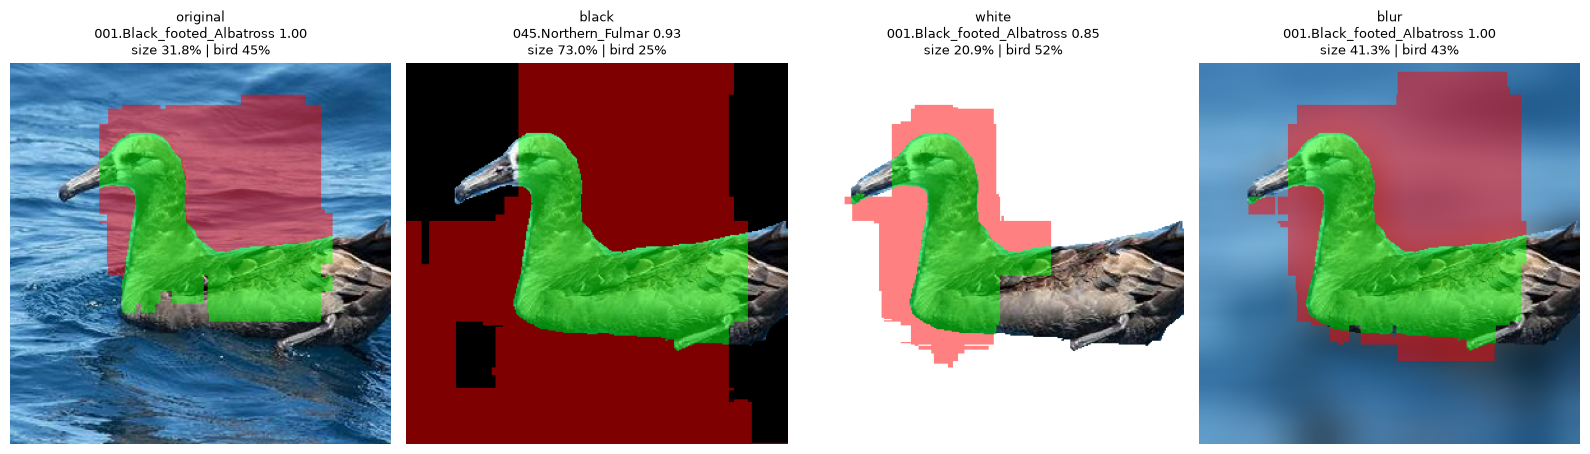

Extracting global explanation:  96%|█████████▌| 8574/8940 [00:59<00:02, 143.38it/s]


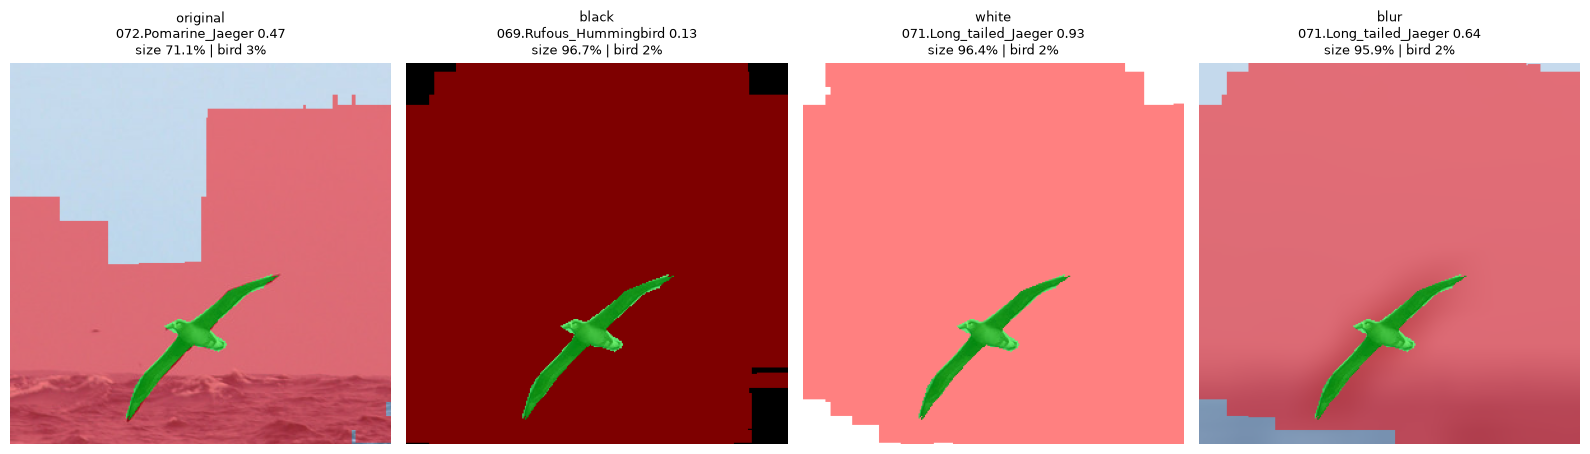

Extracting global explanation:  34%|███▍      | 3033/8940 [00:21<00:41, 142.82it/s]


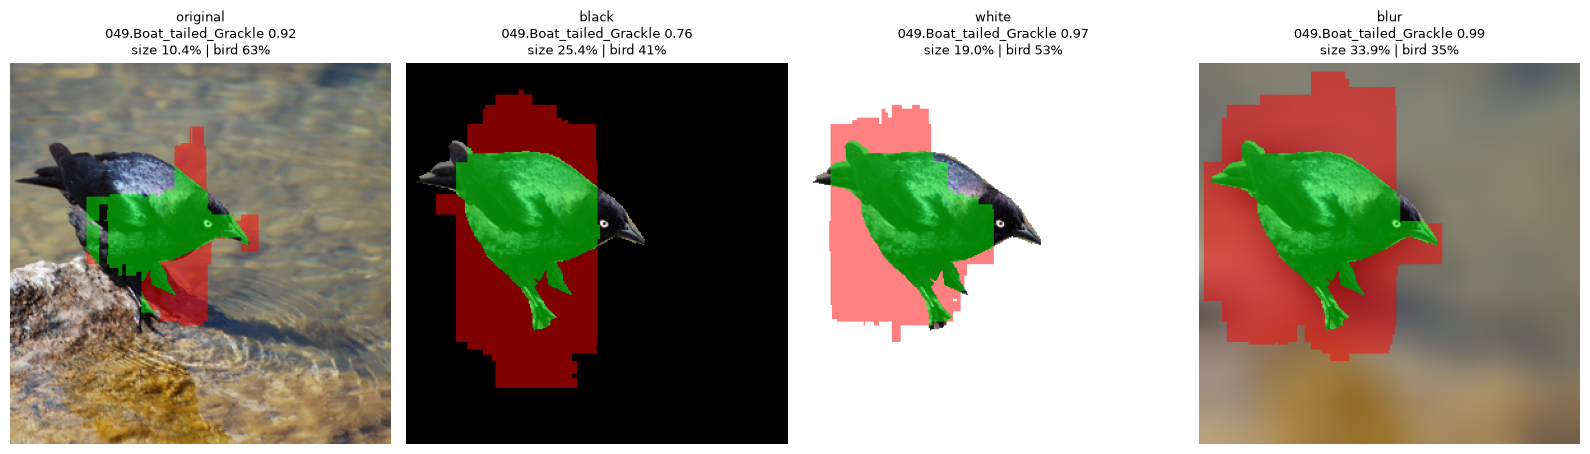

Extracting global explanation:   7%|▋         | 612/8940 [00:04<00:58, 141.71it/s]


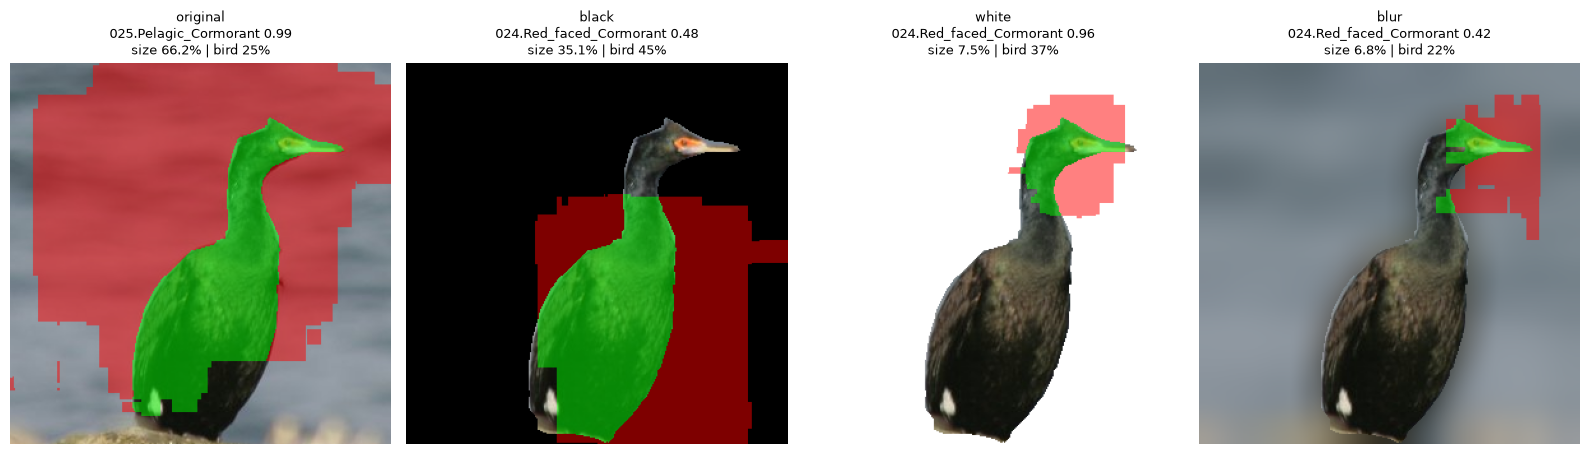

Extracting global explanation:  12%|█▏        | 1094/8940 [00:07<00:54, 143.09it/s]


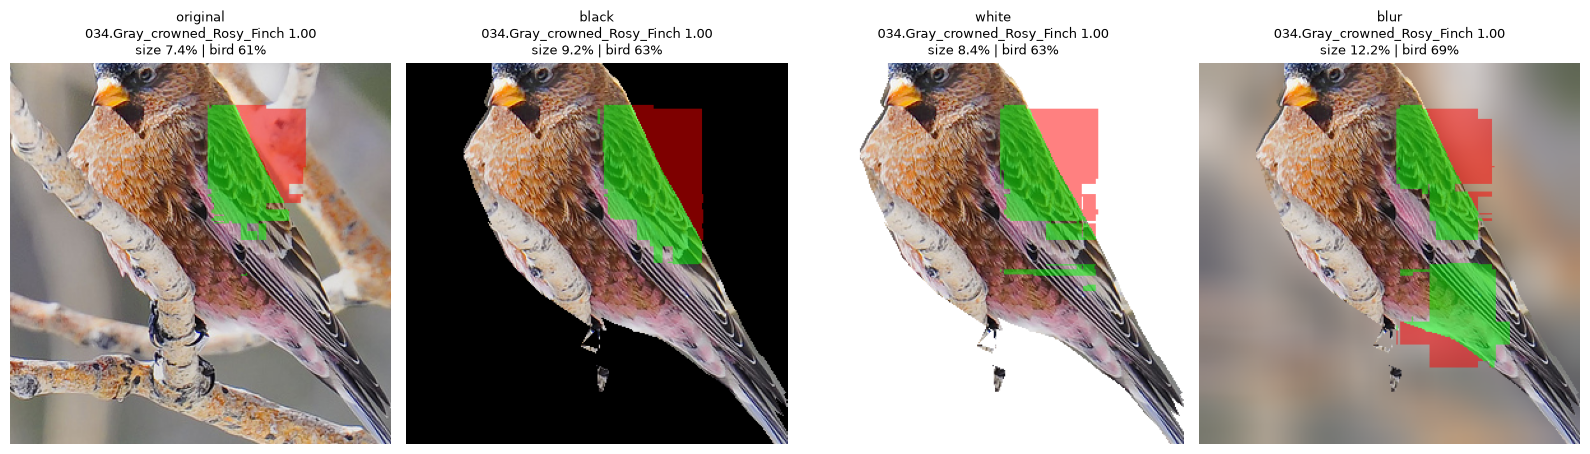

Extracting global explanation:   4%|▍         | 346/8940 [00:02<01:00, 141.56it/s]


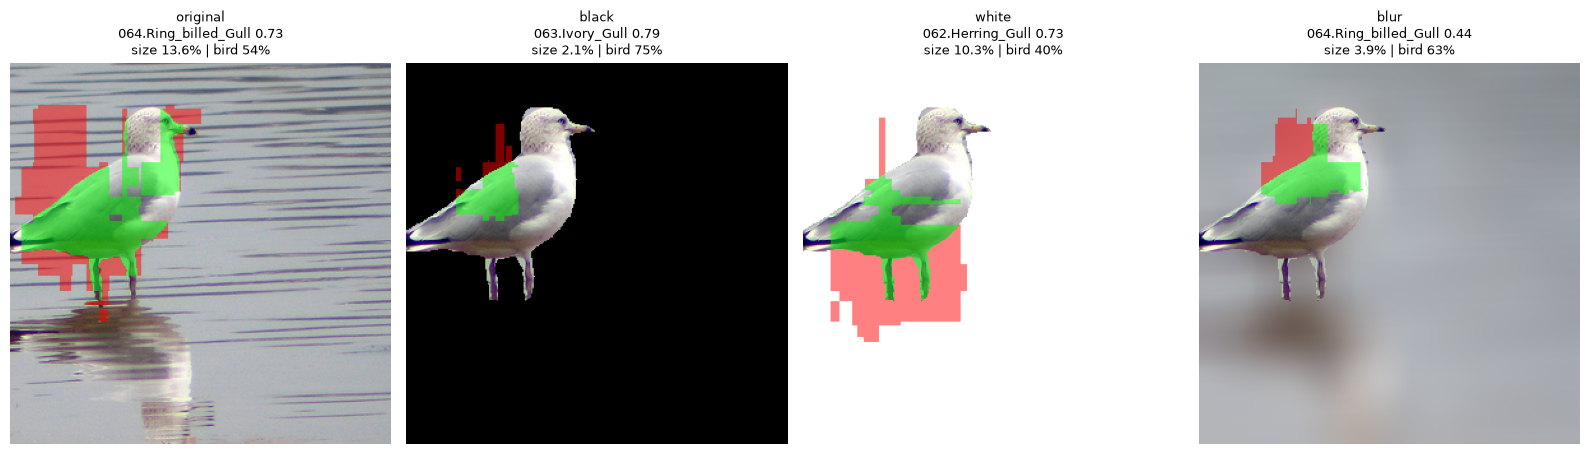

,idx,background,target_class,target_conf,correct,size,bird_share,true_class
0,10,original,001.Black_footed_Albatross,0.999875,True,0.318005,0.454696,001.Black_footed_Albatross
1,10,black,045.Northern_Fulmar,0.933512,False,0.729634,0.254929,001.Black_footed_Albatross
2,10,white,001.Black_footed_Albatross,0.852371,True,0.208722,0.519346,001.Black_footed_Albatross
3,10,blur,001.Black_footed_Albatross,0.997219,True,0.412859,0.429802,001.Black_footed_Albatross
4,0,original,072.Pomarine_Jaeger,0.472976,False,0.711066,0.033522,001.Black_footed_Albatross
5,0,black,069.Rufous_Hummingbird,0.129651,False,0.966880,0.024653,001.Black_footed_Albatross
6,0,white,071.Long_tailed_Jaeger,0.932871,False,0.963971,0.024727,001.Black_footed_Albatross
7,0,blur,071.Long_tailed_Jaeger,0.639010,False,0.959050,0.024854,001.Black_footed_Albatross
8,200,original,049.Boat_tailed_Grackle,0.924784,False,0.104473,0.629872,009.Brewer_Blackbird
9,200,black,049.Boat_tailed_Grackle,0.756720,False,0.253912,0.413965,009.Brewer_Blackbird


In [14]:
rex_rows = rex_swap_test([10, 0, 200, 600, 900, 1800], joint_model, joint_prediction_function, plot=True)
rex_df = pd.DataFrame(rex_rows)
rex_df.drop(columns="explanation")

In [11]:
# Save the ReX results: full rows (with the explanation masks) + a readable table
with open(OUT / "rex_swap_joint.pkl", "wb") as f:
    pickle.dump(rex_rows, f)

rex_df = pd.DataFrame(rex_rows)
rex_df.drop(columns="explanation").to_csv(OUT / "rex_swap_joint.csv", index=False)

# Also save the earlier model-only swap test (concepts and predictions)
df.to_csv(OUT / "swap_test_joint.csv", index=False)

print(sorted(p.name for p in OUT.iterdir()))


with open(OUT / "rex_swap_joint.pkl", "rb") as f:
    rex_rows = pickle.load(f)
rex_df = pd.DataFrame(rex_rows)

NameError: name 'rex_rows' is not defined

- The background changed the predicted class in 3 of 6 images, in both directions: it broke one correct prediction (gull → tern or another gull) and fixed one
wrong one (Pelagic → the correct Red-faced Cormorant).
- The leakage goes through the concepts. When the class changes, the colour concepts move first. Albatross: underparts::grey goes from 0.99 to 0.07 and the
"white" concepts rise to about 0.9, so it becomes a Northern Fulmar. 
- Background brightness changes the result. underparts::grey is 0.99 on the original, 0.59 on white, 0.11 on grey and 0.07 on black. The darker the background, the
lighter the model thinks the bird is.
- The overall scene colour matters, not its detail. A blurred background behaves almost like the original (albatross 0.997, 0 concepts flipped).
- ReX confirms it. On solid backgrounds, explanations keep background pixels when the brightness matters: the Fulmar-on-black explanation covers 73% of the
image, mostly black background.
- A misleading background can cause a wrong prediction. The wrong cormorant prediction needs 66% of the image, mostly sky and sea. With the background
replaced, the correct one needs only about 7%: the red face.
- Close-ups are unaffected: a finch filling the frame gives the same result on every background.

Takeaway: Joint CBMs don't rely only on the bird. Background information leaks in by shifting the concept predictions.


### 4- Large run

**Stage 1:** `swap_test` (model only, fast) on every 10th test image. **Stage 2:** ReX on a subset (~2 min per image), saved after every image so it can resume.

In [13]:
# Stage 1: model-only swap test on every 10th test image (580 images)
from tqdm.auto import tqdm

idx_list = list(range(0, len(test_data), 10))
rows = []
for idx in tqdm(idx_list):
    rows += swap_test([idx], plot=False)

df = pd.DataFrame(rows)
df.to_pickle(OUT / "swap_test_joint_every10.pkl")     # keeps the concept arrays
df.drop(columns=["top_changes", "concepts"]).to_csv(OUT / "swap_test_joint_every10.csv", index=False)
print(len(df), "rows saved")

/mnt/data/conda/envs/rex/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 580/580 [00:30<00:00, 18.81it/s]

2900 rows saved


In [14]:
# Stage 1 summary per background
df.groupby("background")[["correct", "true_conf", "n_flipped", "mean_change"]].mean()

,correct,true_conf,n_flipped,mean_change
background,,,,
black,0.629310,0.583125,5.706897,0.059190
blur,0.756897,0.724884,2.600000,0.030575
grey,0.731034,0.704712,3.213793,0.035978
original,0.793103,0.764120,0.000000,0.000000
white,0.715517,0.682541,3.596552,0.038885


In [15]:
# Stage 2: choose images for ReX: correctness changes on some background + a random stable set
changed = df.groupby("idx")["correct"].nunique() > 1     # correct on some backgrounds, wrong on others

changed_idx = changed[changed].index.tolist()
stable_idx = changed[~changed].index.tolist()

rng = np.random.default_rng(0)
rex_idx = (rng.choice(changed_idx, size=min(40, len(changed_idx)), replace=False).tolist()
           + rng.choice(stable_idx, size=min(20, len(stable_idx)), replace=False).tolist())
print(len(changed_idx), "changed,", len(stable_idx), "stable, running ReX on", len(rex_idx))

188 changed, 392 stable, running ReX on 60


In [16]:
# Stage 2: ReX on the subset, saved after every image. Rerun this cell to resume.
rex_path = OUT / "rex_swap_joint_subset.pkl"
rex_rows = pickle.load(open(rex_path, "rb")) if rex_path.exists() else []
done = {r["idx"] for r in rex_rows}

for idx in tqdm(rex_idx):
    if idx in done:
        continue
    rex_rows += rex_swap_test([idx], joint_model, joint_prediction_function, plot=False)
    with open(rex_path, "wb") as f:
        pickle.dump(rex_rows, f)

rex_df = pd.DataFrame(rex_rows)
rex_df.drop(columns="explanation").to_csv(OUT / "rex_swap_joint_subset.csv", index=False)
print(len(rex_df), "rows saved")

100%|██████████| 60/60 [1:32:26<00:00, 92.45s/it]

240 rows saved
